In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

In C:\Users\hp\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\bmh.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In C:\Users\hp\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In C:\Users\hp\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test_patch.mplstyle: The text.kerning_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.


In [2]:
print("Working folder:", os.getcwd())
print("Files here:", os.listdir())

Working folder: C:\Users\hp
Files here: ['.anaconda', '.conda', '.continuum', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '.ms-ad', 'anaconda3', 'AppData', 'Application Data', 'battery-report.html', 'comparison.png', 'Contacts', 'Cookies', 'Documents', 'Downloads', 'EYU.ipynb', 'Favorites', 'figures', 'Fitting problem.ipynb', 'fitting_curve.png', 'importance.png', 'learning_curve.png', 'Links', 'Local Settings', 'ml_lab_data.xlsx', 'model_performance_results.xlsx', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{95a36084-1d45-11f1-a40b-44253834f388}.TM.blf', 'NTUSER.DAT{95a36084-1d45-11f1-a40b-44253834f388}.TM.blf.cnpf', 'NTUSER.DAT{95a36084-1d45-11f1-a40b-44253834f388}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{95a36084-1d45-11f1-a40b-44253834f388}.TMContainer00000000000000000001.regtrans-ms.cnpf', 'NTUSER.DAT{95a36084-1d45-11f1-a40b-44253834f388}.TMContainer00000000000000000002.regtrans-ms', 'NTUSER.D

In [3]:
df = pd.read_excel("C:/Users/hp/Downloads/customer_purchase_data.xlsx")
df.head()

,Age,Gender,Annual_Salary,Education,Website_Visits,Purchased
0,21.0,Female,74200.0,Graduate,8,0
1,50.0,Male,51300.0,School,6,0
2,45.0,Female,59900.0,Graduate,6,0
3,36.0,Female,56400.0,Postgraduate,7,0
4,36.0,Female,67400.0,School,8,0


In [4]:
rng = np.random.default_rng(42)
n = 400
age = rng.integers(18, 60, n)
sal = rng.normal(60000, 22000, n).clip(15000, 150000).round(-2)
gender = rng.choice(["Male", "Female"], n)
edu = rng.choice(["School", "Graduate", "Postgraduate"], n, p=[.3, .5, .2])
visits = rng.poisson(8, n)
score = (0.09*(age-38) + 0.000035*(sal-60000) + 0.12*(visits-8)
         + 0.4*(edu == "Postgraduate") + rng.normal(0, 0.9, n)
         - 0.6*(((age-38)/12)**2 + ((sal-60000)/25000)**2 < 0.6))
df = pd.DataFrame(dict(Age=age, Gender=gender, Annual_Salary=sal, Education=edu,
                       Website_Visits=visits, Purchased=(score > 0.35).astype(int)))
for col, k in [("Annual_Salary", 15), ("Age", 8)]:
    df.loc[rng.choice(n, k, replace=False), col] = np.nan
df.head()

,Age,Gender,Annual_Salary,Education,Website_Visits,Purchased
0,21.0,Female,74200.0,Graduate,8,0
1,50.0,Male,51300.0,School,6,0
2,45.0,Female,59900.0,Graduate,6,0
3,36.0,Female,56400.0,Postgraduate,7,0
4,36.0,Female,67400.0,School,8,0


In [5]:
print(df.isnull().sum(), "\n")                       # missing values
print(df['Purchased'].value_counts(normalize=True))  # class balance
df.describe()

Age                8
Gender             0
Annual_Salary     15
Education          0
Website_Visits     0
Purchased          0
dtype: int64 

Purchased
0    0.6325
1    0.3675
Name: proportion, dtype: float64


,Age,Annual_Salary,Website_Visits,Purchased
count,392.000000,385.000000,400.000000,400.000000
mean,38.239796,60241.038961,7.915000,0.367500
std,11.866420,21761.844930,2.913588,0.482728
min,18.000000,15000.000000,1.000000,0.000000
25%,28.750000,44900.000000,6.000000,0.000000
50%,37.500000,61100.000000,8.000000,0.000000
75%,49.000000,74000.000000,10.000000,1.000000
max,59.000000,123900.000000,23.000000,1.000000


In [14]:
# Fill missing numeric values with the median
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Annual_Salary'] = df['Annual_Salary'].fillna(df['Annual_Salary'].median())

# Encode categorical columns
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})
df['Education'] = df['Education'].map({'School': 0, 'Graduate': 1, 'Postgraduate': 2})
df.isnull().sum().sum()   # should be 0

np.int64(0)

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('Purchased', axis=1)
y = df['Purchased']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y)

sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)   # fit on train only
X_test_s  = sc.transform(X_test)
print(X_train.shape, X_test.shape)

(300, 8) (100, 8)


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

models = {
    "Logistic Regression": LogisticRegression(),
    "Naive Bayes":         GaussianNB(),
    "K-NN (k=5)":          KNeighborsClassifier(n_neighbors=5),
    "SVM (linear)":        SVC(kernel='linear'),
    "Kernel SVM (RBF)":    SVC(kernel='rbf', gamma='scale'),
    "Decision Tree":       DecisionTreeClassifier(max_depth=4, random_state=0),
    "LDA":                 LinearDiscriminantAnalysis(),
    "QDA":                 QuadraticDiscriminantAnalysis(),
}

fitted = {}
for name, m in models.items():
    m.fit(X_train_s, y_train)
    fitted[name] = m
print("All models trained")

All models trained


Best model: SVM (linear)


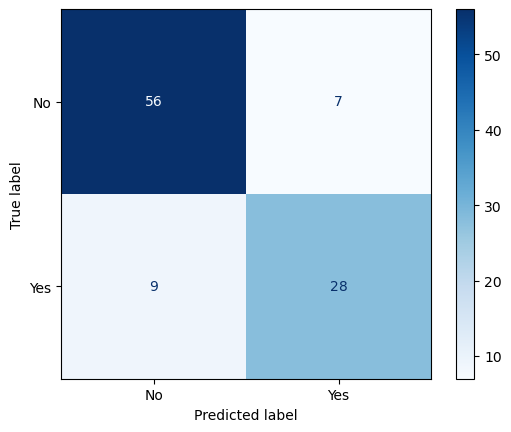

              precision    recall  f1-score   support

           0       0.86      0.89      0.88        63
           1       0.80      0.76      0.78        37

    accuracy                           0.84       100
   macro avg       0.83      0.82      0.83       100
weighted avg       0.84      0.84      0.84       100



In [14]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

best = res['Test Acc'].idxmax()
print("Best model:", best)
pred = fitted[best].predict(X_test_s)

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["No","Yes"]).plot(cmap='Blues')
plt.show()
print(classification_report(y_test, pred))

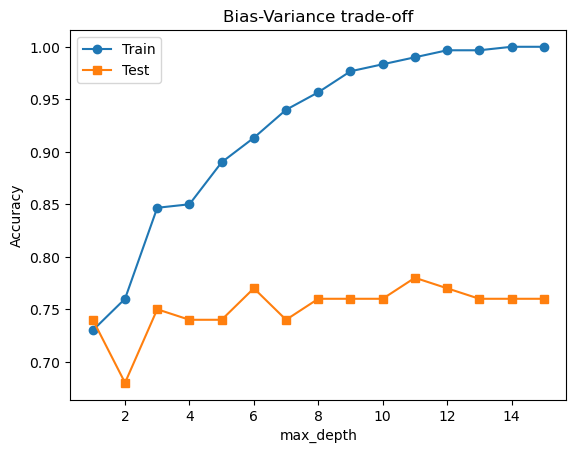

Best depth: 11


In [15]:
depths = range(1, 16)
tr, te = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    tr.append(t.score(X_train, y_train))
    te.append(t.score(X_test, y_test))

plt.plot(depths, tr, 'o-', label='Train')
plt.plot(depths, te, 's-', label='Test')
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.legend()
plt.title("Bias-Variance trade-off"); plt.show()
print("Best depth:", depths[int(np.argmax(te))])

In [16]:
pip install pandas openpyxl scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


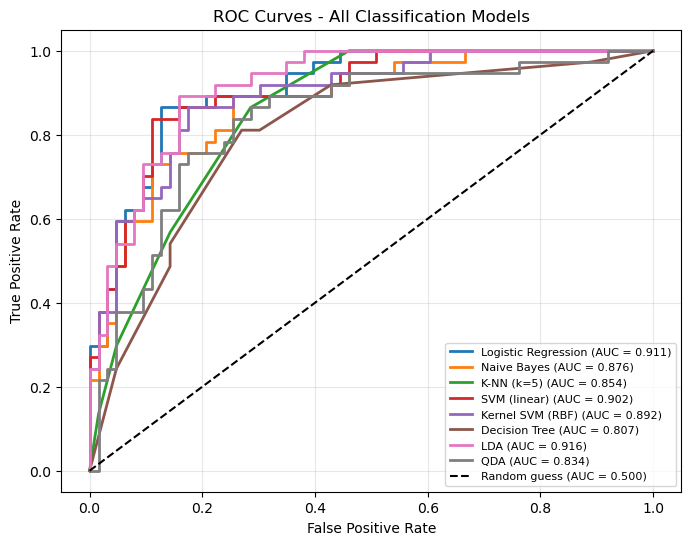

                       AUC
LDA                  0.916
Logistic Regression  0.911
SVM (linear)         0.902
Kernel SVM (RBF)     0.892
Naive Bayes          0.876
K-NN (k=5)           0.854
QDA                  0.834
Decision Tree        0.807


In [18]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))
auc_table = {}

for name, m in fitted.items():
    # Use probabilities when the model has them, otherwise use decision scores (SVM)
    if hasattr(m, "predict_proba"):
        score = m.predict_proba(X_test_s)[:, 1]
    else:
        score = m.decision_function(X_test_s)

    fpr, tpr, _ = roc_curve(y_test, score)
    auc = roc_auc_score(y_test, score)
    auc_table[name] = auc
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label="Random guess (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - All Classification Models")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.show()

print(pd.Series(auc_table).sort_values(ascending=False).round(3).to_frame("AUC"))